In [433]:
# 그래프 관련
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np

# 머신러닝 관련
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier  #평균절대값오차
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_absolute_error
from sklearn.linear_model import Ridge
from sklearn.preprocessing import OneHotEncoder

In [434]:
## 다중회귀 - 특성이 여러 개일 때
df = pd.read_csv('data/MultipleLinearRegressionData.csv')
df.head(3)

,hour,absent,place,score
0,0.5,3,Home,10
1,1.2,4,Library,8
2,1.8,2,Cafe,14


In [435]:
data = df.iloc[:,:2]
data = np.array(data)
label = df['score']


In [436]:
place=df['place'].to_numpy().reshape(-1,1)
encoder = OneHotEncoder(sparse_output=False,drop='first')
result = encoder.fit_transform(place)

In [437]:
# data + result
total_data = np.concatenate((data,result), axis=1)

In [438]:
train_data,test_data,train_label,test_label = train_test_split(total_data,label,random_state=20)

In [439]:
poly = PolynomialFeatures(degree=3,include_bias=False)  #include_bias=False 학습의미없는 데이터 1를 생략
poly.fit(train_data)
train_poly = poly.transform(train_data)
test_poly = poly.transform(test_data)
train_poly[:2]

array([[  6.2  ,   1.   ,   0.   ,   1.   ,  38.44 ,   6.2  ,   0.   ,
          6.2  ,   1.   ,   0.   ,   1.   ,   0.   ,   0.   ,   1.   ,
        238.328,  38.44 ,   0.   ,  38.44 ,   6.2  ,   0.   ,   6.2  ,
          0.   ,   0.   ,   6.2  ,   1.   ,   0.   ,   1.   ,   0.   ,
          0.   ,   1.   ,   0.   ,   0.   ,   0.   ,   1.   ],
       [  8.4  ,   1.   ,   1.   ,   0.   ,  70.56 ,   8.4  ,   8.4  ,
          0.   ,   1.   ,   1.   ,   0.   ,   1.   ,   0.   ,   0.   ,
        592.704,  70.56 ,  70.56 ,   0.   ,   8.4  ,   8.4  ,   0.   ,
          8.4  ,   0.   ,   0.   ,   1.   ,   1.   ,   0.   ,   1.   ,
          0.   ,   0.   ,   1.   ,   0.   ,   0.   ,   0.   ]])

In [440]:
# 1차원
lr = LinearRegression()
lr.fit(train_data, train_label)
predict = lr.predict(test_data)
print('점수 예측: ', predict)

score = lr.score(train_data, train_label)
score2 = lr.score(test_data, test_label)
print(f'정확도:{score*100}%, {score2*100}%')

점수 예측:  [74.67906401 65.37800568 55.85968663 24.55625793 11.28991928]
정확도:96.78129791370543%, 98.8011581292527%


In [441]:
# 2차원
lr = LinearRegression()
lr.fit(train_poly, train_label)
predict = lr.predict(test_poly)
print('점수 예측: ', predict)

score = lr.score(train_poly, train_label)
score2 = lr.score(test_poly, test_label)
print(f'정확도:{score*100}%, {score2*100}%')

점수 예측:  [73.47673124 72.61265648 54.01818497 29.30433085  2.14141227]
정확도:100.0%, 95.79899089690345%


In [442]:
# StandartScaler
ss = StandardScaler()
ss.fit(train_poly)
train_scaled = ss.transform(train_poly)
test_scaled = ss.transform(test_poly)

In [443]:
alpha_list = [0.001,0.01,0.1,1,10,100]
train_score = []
test_score = []

for alpha in alpha_list:

    ridge = Ridge(alpha=alpha)
    ridge.fit(train_scaled,train_label)
    score = ridge.score(train_scaled, train_label)
    score2 = ridge.score(test_scaled, test_label)
    train_score.append(score)
    test_score.append(score2)
    
print(f'정확도:{score*100}%, {score2*100}%')


정확도:60.08325973729978%, 21.433534091169047%


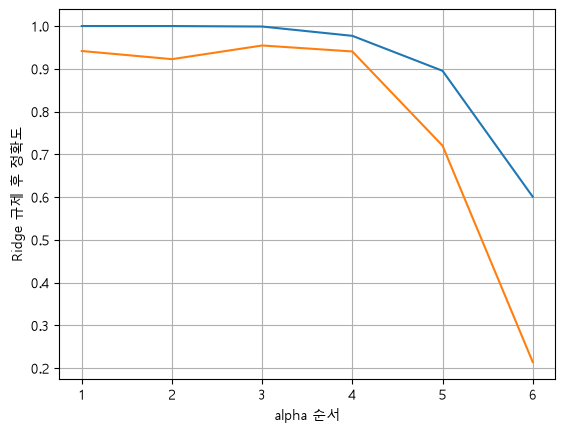

In [444]:
# 그래프 그리기
no_list = [1,2,3,4,5,6]
plt.plot(no_list,train_score)
plt.plot(no_list,test_score)
plt.grid()
plt.xlabel('alpha 순서')
plt.ylabel('Ridge 규제 후 정확도')
plt.show()